# Wetteranalyse: Berlin 2025

In diesem Notebook untersuchen wir historische Tageswetterdaten für Berlin. Wir laden sie über die kostenlose Open-Meteo-Archiv-API, fassen Temperatur und Niederschlag monatlich zusammen und stellen die Entwicklung grafisch dar.

**Zeitraum:** 1. Januar bis 31. Dezember 2025  
**Ort:** Berlin, ungefähr 52.52° N, 13.405° E

Führe die Zellen der Reihe nach mit **Shift+Enter** aus. Für den Datenabruf wird eine Internetverbindung benötigt.

## 1. Pakete vorbereiten

Wir nutzen **pandas** für die Tabelle, **requests** für den Abruf und **matplotlib** für Diagramme. Die folgende Notebook-Zelle installiert die Pakete in der Umgebung des aktiven Kernels. Wenn sie bereits installiert sind, bleibt der Aufruf unproblematisch.

In [5]:
%pip install pandas requests matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Wetterdaten abrufen

Open-Meteo stellt historische Wetterdaten ohne API-Schlüssel bereit. Wir fragen Tagesmittel-, Höchst- und Tiefsttemperatur sowie die tägliche Niederschlagssumme ab. Die Koordinaten stehen für einen Messpunkt nahe dem Berliner Stadtzentrum; die Daten beschreiben daher nicht jede Ecke der Stadt.

In [6]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [7]:
url = "https://archive-api.open-meteo.com/v1/archive"
parameter = {
    "latitude": 52.52,
    "longitude": 13.405,
    "start_date": "2025-01-01",
    "end_date": "2025-12-31",
    "daily": [
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min",
        "precipitation_sum",
    ],
    "timezone": "Europe/Berlin",
}

antwort = requests.get(url, params=parameter, timeout=30)
antwort.raise_for_status()
daten = antwort.json()

df = pd.DataFrame(daten["daily"])
df["time"] = pd.to_datetime(df["time"])
df = df.rename(columns={
    "time": "Datum",
    "temperature_2m_mean": "Temperatur_Mittel_C",
    "temperature_2m_max": "Temperatur_Max_C",
    "temperature_2m_min": "Temperatur_Min_C",
    "precipitation_sum": "Niederschlag_mm",
})

print(f"Geladene Tage: {len(df)}")
df.head()

Geladene Tage: 365


,Datum,Temperatur_Mittel_C,Temperatur_Max_C,Temperatur_Min_C,Niederschlag_mm
0,2025-01-01,4.8,6.9,0.6,0.1
1,2025-01-02,4.0,6.7,0.9,4.1
2,2025-01-03,0.8,2.4,-1.5,3.1
3,2025-01-04,-1.1,0.8,-2.7,0.0
4,2025-01-05,-1.0,1.4,-2.5,9.3


## 3. Monatswerte berechnen

Für jeden Monat berechnen wir die durchschnittliche Tagesmitteltemperatur und addieren den Niederschlag. Die Temperatur wird also über alle gelieferten Tage eines Monats gemittelt, während beim Niederschlag die Tagessummen aufaddiert werden.

In [8]:
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
df["Monat_Nr"] = df["Datum"].dt.month

monatswerte = (
    df.groupby("Monat_Nr", as_index=False)
    .agg(
        Temperatur_Mittel_C=("Temperatur_Mittel_C", "mean"),
        Niederschlag_mm=("Niederschlag_mm", "sum"),
    )
)
monatswerte["Monat"] = monatswerte["Monat_Nr"].map(
    dict(enumerate(monatsnamen, start=1))
)
monatswerte[["Monat", "Temperatur_Mittel_C", "Niederschlag_mm"]].round(1)

,Monat,Temperatur_Mittel_C,Niederschlag_mm
0,Jan,2.2,82.5
1,Feb,0.6,22.3
2,Mär,6.2,13.5
3,Apr,12.0,15.8
4,Mai,13.8,24.5
5,Jun,19.7,48.6
6,Jul,19.5,185.8
7,Aug,18.8,40.4
8,Sep,15.7,53.9
9,Okt,10.3,54.3


## 4. Wetter im Jahresverlauf

Das erste Diagramm zeigt die monatliche Durchschnittstemperatur, das zweite die Niederschlagsmenge. So lassen sich Jahreszeiten und besonders niederschlagsreiche Monate auf einen Blick vergleichen.

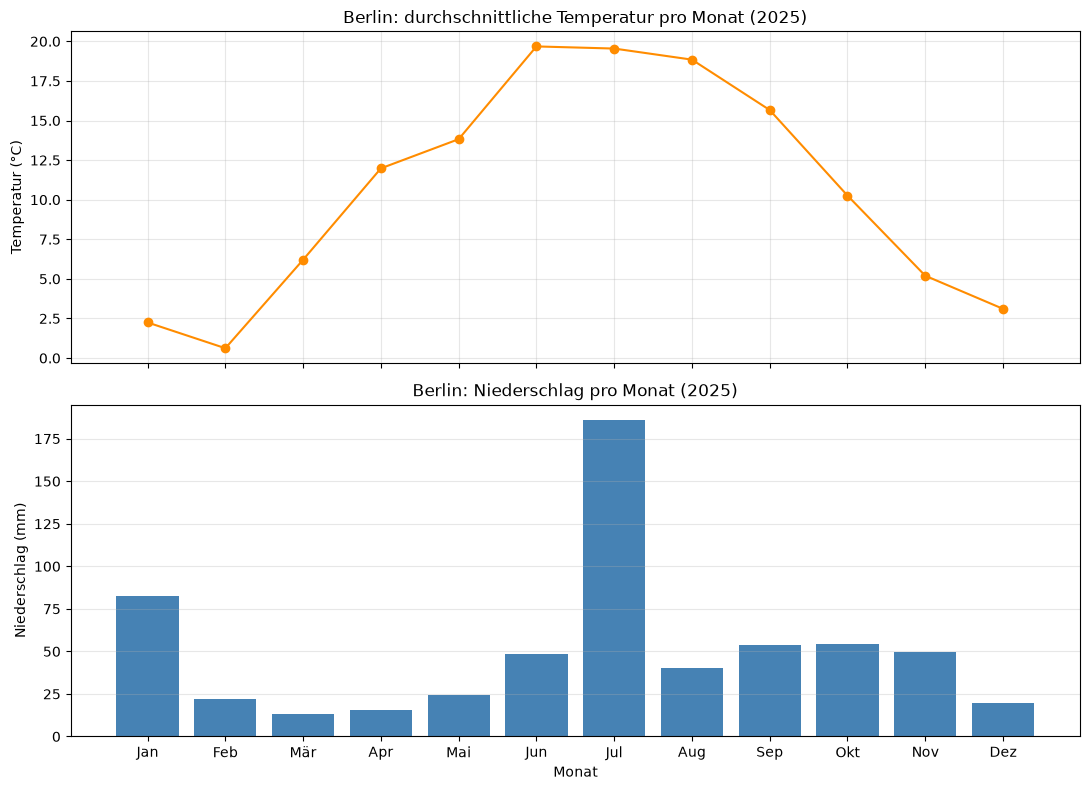

In [9]:
fig, achsen = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

achsen[0].plot(
    monatswerte["Monat"],
    monatswerte["Temperatur_Mittel_C"],
    marker="o",
    color="darkorange",
)
achsen[0].set_title("Berlin: durchschnittliche Temperatur pro Monat (2025)")
achsen[0].set_ylabel("Temperatur (°C)")
achsen[0].grid(True, alpha=0.3)

achsen[1].bar(monatswerte["Monat"], monatswerte["Niederschlag_mm"], color="steelblue")
achsen[1].set_title("Berlin: Niederschlag pro Monat (2025)")
achsen[1].set_ylabel("Niederschlag (mm)")
achsen[1].set_xlabel("Monat")
achsen[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
waermster_monat = monatswerte.loc[monatswerte["Temperatur_Mittel_C"].idxmax()]
kaeltester_monat = monatswerte.loc[monatswerte["Temperatur_Mittel_C"].idxmin()]
nassester_monat = monatswerte.loc[monatswerte["Niederschlag_mm"].idxmax()]

print(f"Mittlere Temperatur im Jahr: {df['Temperatur_Mittel_C'].mean():.1f} °C")
print(f"Wärmster Monat: {waermster_monat['Monat']} ({waermster_monat['Temperatur_Mittel_C']:.1f} °C)")
print(f"Kältester Monat: {kaeltester_monat['Monat']} ({kaeltester_monat['Temperatur_Mittel_C']:.1f} °C)")
print(f"Niederschlag im Jahr: {df['Niederschlag_mm'].sum():.1f} mm")
print(f"Niederschlagsreichster Monat: {nassester_monat['Monat']} ({nassester_monat['Niederschlag_mm']:.1f} mm)")

Mittlere Temperatur im Jahr: 10.7 °C
Wärmster Monat: Jun (19.7 °C)
Kältester Monat: Feb (0.6 °C)
Niederschlag im Jahr: 610.5 mm
Niederschlagsreichster Monat: Jul (185.8 mm)


## 5. Ergebnisse einordnen

Die ausgegebenen Werte zeigen den wärmsten und kältesten Monat sowie den Monat mit dem meisten Niederschlag. Das sind Beschreibungen dieses Jahres und dieses Koordinatenpunkts, keine Vorhersage und kein langfristiger Klimatrend. Für Klimavergleiche sollte man mehrere Jahrzehnte betrachten.

**Zum Ausprobieren:** Ändere im Datenabruf `start_date` und `end_date` auf ein anderes vollständiges Jahr und führe danach alle Zellen erneut aus. Vergleiche, wie sich Monatsverlauf und Jahreswerte unterscheiden.

## 6. Vergleich mit Messdaten des DWD

Jetzt vergleichen wir Open-Meteo mit den täglichen Klimadaten des **Deutschen Wetterdienstes (DWD)** für die Station **Berlin-Tempelhof (Stations-ID 00433)**. Das DWD-Archiv reicht für diese Station bis zum 31.12.2025.

Wir gleichen beide Quellen über das Datum ab und vergleichen Temperaturmittel und Niederschlag. Das sind unterschiedliche Messpunkte: Open-Meteo nutzt die Koordinaten aus Abschnitt 2, der DWD eine Messstation in Tempelhof. Abweichungen sind daher erwartbar und bedeuten nicht automatisch, dass eine Quelle fehlerhaft ist.

Die DWD-Datei stammt aus dem [DWD Climate Data Center](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/).

In [11]:
import io
import zipfile

dwd_url = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/tageswerte_KL_00433_19480101_20251231_hist.zip"
antwort_dwd = requests.get(dwd_url, timeout=60)
antwort_dwd.raise_for_status()

with zipfile.ZipFile(io.BytesIO(antwort_dwd.content)) as archiv:
    csv_name = next(
        name for name in archiv.namelist()
        if name.startswith("produkt_klima_tag_") and name.endswith(".txt")
    )
    with archiv.open(csv_name) as datei:
        dwd = pd.read_csv(
            datei,
            sep=";",
            skipinitialspace=True,
            usecols=["MESS_DATUM", "RSK", "TMK", "TXK", "TNK"],
            na_values=[-999, "-999"],
        )

dwd["Datum"] = pd.to_datetime(dwd["MESS_DATUM"].astype(str), format="%Y%m%d")
dwd = dwd.rename(columns={
    "TMK": "DWD_Temperatur_Mittel_C",
    "TXK": "DWD_Temperatur_Max_C",
    "TNK": "DWD_Temperatur_Min_C",
    "RSK": "DWD_Niederschlag_mm",
})
dwd = dwd[dwd["Datum"].between(df["Datum"].min(), df["Datum"].max())].copy()

print(f"DWD-Tage im Analysezeitraum: {len(dwd)}")
dwd.head()

DWD-Tage im Analysezeitraum: 365


,MESS_DATUM,DWD_Niederschlag_mm,DWD_Temperatur_Mittel_C,DWD_Temperatur_Max_C,DWD_Temperatur_Min_C,Datum
28125,20250101,0.8,5.5,8.5,2.0,2025-01-01
28126,20250102,0.2,4.6,8.4,2.0,2025-01-02
28127,20250103,0.4,1.4,3.8,-1.0,2025-01-03
28128,20250104,0.0,0.0,0.6,-0.8,2025-01-04
28129,20250105,10.9,-0.8,1.2,-2.6,2025-01-05


Wir führen die Tabellen über das Datum zusammen. Als Kennzahl verwenden wir den **mittleren absoluten Fehler (MAE)**: Er beschreibt die durchschnittliche Größe der Tagesabweichung, ohne dass sich positive und negative Abweichungen gegenseitig aufheben. Fehlende Messwerte lassen wir für die jeweilige Kennzahl aus.

In [12]:
vergleich = df[
    ["Datum", "Temperatur_Mittel_C", "Niederschlag_mm"]
].merge(
    dwd[["Datum", "DWD_Temperatur_Mittel_C", "DWD_Niederschlag_mm"]],
    on="Datum",
    how="inner",
)

temperatur_tage = vergleich.dropna(
    subset=["Temperatur_Mittel_C", "DWD_Temperatur_Mittel_C"]
)
niederschlag_tage = vergleich.dropna(
    subset=["Niederschlag_mm", "DWD_Niederschlag_mm"]
)

mae_temperatur = (
    temperatur_tage["Temperatur_Mittel_C"]
    - temperatur_tage["DWD_Temperatur_Mittel_C"]
).abs().mean()
mae_niederschlag = (
    niederschlag_tage["Niederschlag_mm"]
    - niederschlag_tage["DWD_Niederschlag_mm"]
).abs().mean()

print(f"Gemeinsame Tage: {len(vergleich)}")
print(f"Tage mit beiden Temperaturwerten: {len(temperatur_tage)}")
print(f"Temperatur-MAE: {mae_temperatur:.2f} °C")
print(f"Tage mit beiden Niederschlagswerten: {len(niederschlag_tage)}")
print(f"Niederschlags-MAE: {mae_niederschlag:.2f} mm pro Tag")

Gemeinsame Tage: 365
Tage mit beiden Temperaturwerten: 365
Temperatur-MAE: 0.63 °C
Tage mit beiden Niederschlagswerten: 365
Niederschlags-MAE: 1.01 mm pro Tag


In [13]:
temperatur_tage = temperatur_tage.copy()
niederschlag_tage = niederschlag_tage.copy()
temperatur_tage["Monat_Nr"] = temperatur_tage["Datum"].dt.month
niederschlag_tage["Monat_Nr"] = niederschlag_tage["Datum"].dt.month

monat_temperatur = temperatur_tage.groupby("Monat_Nr").agg(
    OpenMeteo_Temperatur_C=("Temperatur_Mittel_C", "mean"),
    DWD_Temperatur_C=("DWD_Temperatur_Mittel_C", "mean"),
)
monat_niederschlag = niederschlag_tage.groupby("Monat_Nr").agg(
    OpenMeteo_Niederschlag_mm=("Niederschlag_mm", "sum"),
    DWD_Niederschlag_mm=("DWD_Niederschlag_mm", "sum"),
)
vergleich_monat = monat_temperatur.join(monat_niederschlag, how="outer").reset_index()
vergleich_monat["Monat"] = vergleich_monat["Monat_Nr"].map(
    dict(enumerate(monatsnamen, start=1))
)
vergleich_monat.round(1)

,Monat_Nr,OpenMeteo_Temperatur_C,DWD_Temperatur_C,OpenMeteo_Niederschlag_mm,DWD_Niederschlag_mm,Monat
0,1,2.2,3.1,82.5,54.9,Jan
1,2,0.6,1.7,22.3,16.0,Feb
2,3,6.2,7.1,13.5,8.7,Mär
3,4,12.0,12.2,15.8,13.7,Apr
4,5,13.8,13.8,24.5,33.8,Mai
5,6,19.7,19.7,48.6,34.6,Jun
6,7,19.5,19.8,185.8,127.4,Jul
7,8,18.8,19.1,40.4,32.6,Aug
8,9,15.7,16.2,53.9,35.1,Sep
9,10,10.3,10.6,54.3,44.8,Okt


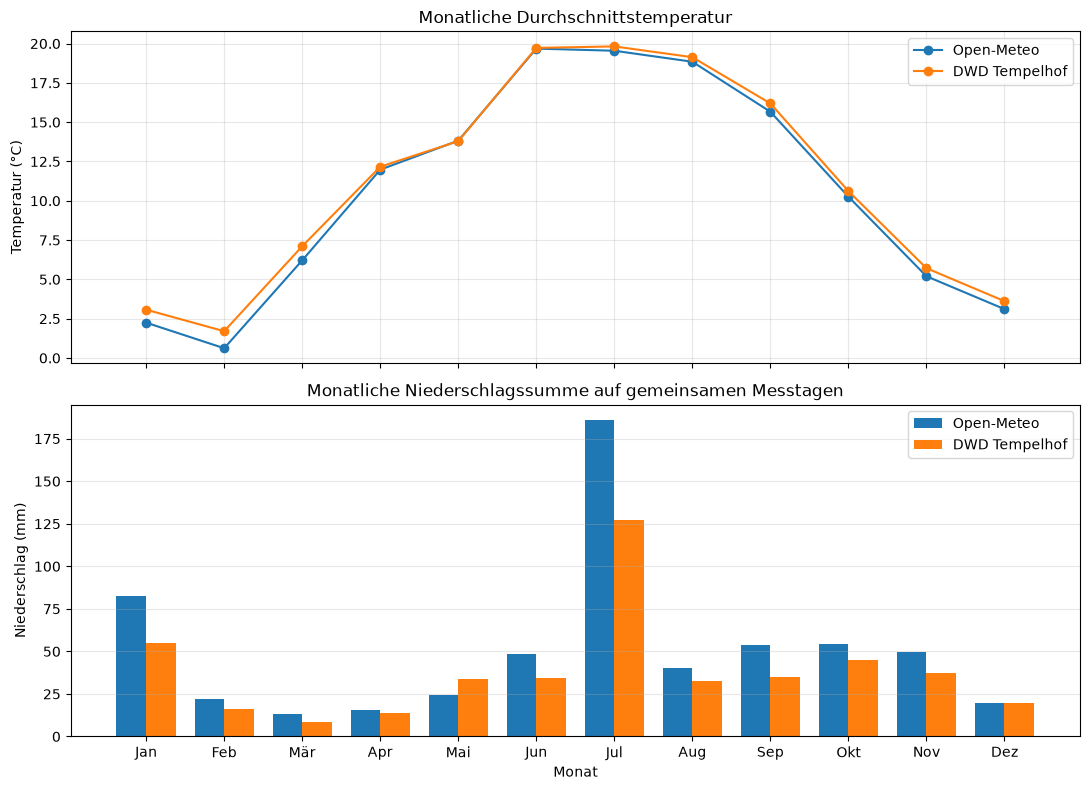

In [15]:
positionen = list(range(len(vergleich_monat)))
breite = 0.38
fig, achsen = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

achsen[0].plot(
    positionen,
    vergleich_monat["OpenMeteo_Temperatur_C"],
    marker="o",
    label="Open-Meteo",
)
achsen[0].plot(
    positionen,
    vergleich_monat["DWD_Temperatur_C"],
    marker="o",
    label="DWD Tempelhof",
)
achsen[0].set_title("Monatliche Durchschnittstemperatur")
achsen[0].set_ylabel("Temperatur (°C)")
achsen[0].legend()
achsen[0].grid(True, alpha=0.3)

achsen[1].bar(
    [position - breite / 2 for position in positionen],
    vergleich_monat["OpenMeteo_Niederschlag_mm"],
    width=breite,
    label="Open-Meteo",
)
achsen[1].bar(
    [position + breite / 2 for position in positionen],
    vergleich_monat["DWD_Niederschlag_mm"],
    width=breite,
    label="DWD Tempelhof",
)
achsen[1].set_title("Monatliche Niederschlagssumme auf gemeinsamen Messtagen")
achsen[1].set_ylabel("Niederschlag (mm)")
achsen[1].set_xticks(positionen, vergleich_monat["Monat"])
achsen[1].set_xlabel("Monat")
achsen[1].legend()
achsen[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()